# Phase 5 — Forgetting-Aware PEFT Trade-off Analysis

CPU-only analysis of the completed 3-seed results (42, 123, 2026) for LoRA, AdaLoRA and DoRA.

**Adaptation:** SAMSum ROUGE-L gain (higher is better)  
**Retention:** BoolQ, PIQA, ARC-Easy, MMLU forgetting and WikiText-2 PPL increase (lower is better)

No training or model evaluation is performed. Composite scores use per-probe normalization because accuracy gaps and perplexity are on different scales. Sensitivity and Pareto analyses avoid relying on one arbitrary weighting. Results are descriptive over 3 seeds.

In [1]:
from google.colab import drive
drive.mount("/content/drive", force_remount=False)

from pathlib import Path
import json, numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT=Path("/content/drive/MyDrive/forgetting-aware-peft")
INPUT=ROOT/"final_analysis"/"three_seed_per_seed_results.csv"
OUT=ROOT/"phase5_forgetting_aware"
RESULTS=OUT/"results"; PLOTS=OUT/"plots"
RESULTS.mkdir(parents=True,exist_ok=True); PLOTS.mkdir(parents=True,exist_ok=True)
print("Input exists:",INPUT.exists())
assert INPUT.exists()

Mounted at /content/drive
Input exists: True


In [2]:
df=pd.read_csv(INPUT)
cols=["seed","method","samsum_rl_gain","boolq_forgetting","piqa_forgetting",
      "arc_forgetting","mmlu_forgetting","wikitext_ppl_increase"]
assert all(c in df for c in cols)
df=df[cols].copy(); df["method"]=df["method"].str.lower()
assert len(df)==9 and set(df.seed.astype(int))=={42,123,2026}
assert set(df.method)=={"lora","adalora","dora"}
assert (df.groupby("method").seed.nunique()==3).all()
assert not df.isna().any().any()
print("9-run integrity check PASSED ✅")
display(df.sort_values(["method","seed"]))

9-run integrity check PASSED ✅


,seed,method,samsum_rl_gain,boolq_forgetting,piqa_forgetting,arc_forgetting,mmlu_forgetting,wikitext_ppl_increase
0,42,adalora,0.067553,0.006,0.000,0.004,-0.004,-0.004653
1,123,adalora,0.049176,-0.004,-0.004,0.002,0.000,-0.002068
2,2026,adalora,0.045899,-0.010,0.004,-0.006,0.006,-0.004998
3,42,dora,0.110880,-0.010,-0.016,0.002,-0.010,0.961324
4,123,dora,0.097309,-0.030,-0.020,0.006,-0.002,1.018196
5,2026,dora,0.102607,-0.018,-0.008,0.026,0.012,0.935680
6,42,lora,0.098770,-0.008,-0.016,0.002,-0.006,0.827144
7,123,lora,0.097577,-0.034,-0.020,0.006,-0.002,0.937861
8,2026,lora,0.099880,-0.022,-0.014,0.024,0.006,0.873994


In [3]:
metrics=cols[2:]
summary=df.groupby("method")[metrics].agg(["mean","std"])
summary.to_csv(RESULTS/"descriptive_mean_sd.csv")
display(summary)

samsum_rl_gain           boolq_forgetting           piqa_forgetting  \
                  mean       std             mean       std            mean   
method                                                                        
adalora       0.054210  0.011671        -0.002667  0.008083        0.000000   
dora          0.103598  0.006840        -0.019333  0.010066       -0.014667   
lora          0.098742  0.001152        -0.021333  0.013013       -0.016667   

                  arc_forgetting           mmlu_forgetting            \
              std           mean       std            mean       std   
method                                                                 
adalora  0.004000       0.000000  0.005292        0.000667  0.005033   
dora     0.006110       0.011333  0.012858        0.000000  0.011136   
lora     0.003055       0.010667  0.011719       -0.000667  0.006110   

        wikitext_ppl_increase            
                         mean       std  
method                                   
adalora             -0.003906  0.001601  
dora                 0.971733  0.042231  
lora                 0.879666  0.055576

In [4]:
# Normalize method-level means. Lower forgetting is better.
means=df.groupby("method")[metrics].mean().reset_index()
ret=["boolq_forgetting","piqa_forgetting","arc_forgetting","mmlu_forgetting","wikitext_ppl_increase"]

def mm_loss(s):
    lo,hi=s.min(),s.max()
    return pd.Series(np.zeros(len(s)),index=s.index) if np.isclose(lo,hi) else (s-lo)/(hi-lo)

norm=means[["method"]].copy()
for c in ret: norm[c+"_norm_loss"]=mm_loss(means[c])
norm["retention_loss"]=norm[[c+"_norm_loss" for c in ret]].mean(axis=1)
norm["retention_score"]=1-norm["retention_loss"]
a=means.samsum_rl_gain
norm["adaptation_score"]=1.0 if np.isclose(a.min(),a.max()) else (a-a.min())/(a.max()-a.min())
analysis=means.merge(norm,on="method")
analysis.to_csv(RESULTS/"normalized_tradeoff_components.csv",index=False)
display(analysis[["method","samsum_rl_gain","adaptation_score","retention_score"]])

,method,samsum_rl_gain,adaptation_score,retention_score
0,adalora,0.054210,0.00000,0.400000
1,dora,0.103598,1.00000,0.454571
2,lora,0.098742,0.90168,0.630638


In [5]:
# Pareto efficiency: maximize adaptation and retention.
pts=analysis[["method","adaptation_score","retention_score"]].copy()
def dominated(i):
    ai,ri=pts.loc[i,["adaptation_score","retention_score"]]
    for j in pts.index:
        if j!=i:
            aj,rj=pts.loc[j,["adaptation_score","retention_score"]]
            if aj>=ai and rj>=ri and (aj>ai or rj>ri): return True
    return False
pts["pareto_efficient"]=[not dominated(i) for i in pts.index]
pts.to_csv(RESULTS/"pareto_analysis.csv",index=False)
display(pts)

,method,adaptation_score,retention_score,pareto_efficient
0,adalora,0.00000,0.400000,False
1,dora,1.00000,0.454571,True
2,lora,0.90168,0.630638,True


In [6]:
# Weight sensitivity: w=0 adaptation only; w=1 retention only.
rows=[]
for w in np.linspace(0,1,101):
    for _,r in pts.iterrows():
        rows.append({"retention_weight":float(w),"method":r.method,
                     "score":float((1-w)*r.adaptation_score+w*r.retention_score)})
sens=pd.DataFrame(rows); sens["winner"]=False
for w,g in sens.groupby("retention_weight"):
    sens.loc[g.index,"winner"]=np.isclose(g.score,g.score.max())
sens.to_csv(RESULTS/"weight_sensitivity.csv",index=False)

equal=sens[np.isclose(sens.retention_weight,.5)].sort_values("score",ascending=False)
ranges=sens[sens.winner].groupby("method").retention_weight.agg(["min","max","count"]).reset_index()
ranges.to_csv(RESULTS/"winner_weight_ranges.csv",index=False)
print("Equal-weight descriptive ranking:"); display(equal[["method","score"]])
print("Optimal weight ranges (ties included):"); display(ranges)

Equal-weight descriptive ranking:


,method,score
152,lora,0.766159
151,dora,0.727286
150,adalora,0.200000


Optimal weight ranges (ties included):


,method,min,max,count
0,dora,0.00,0.35,36
1,lora,0.36,1.00,65


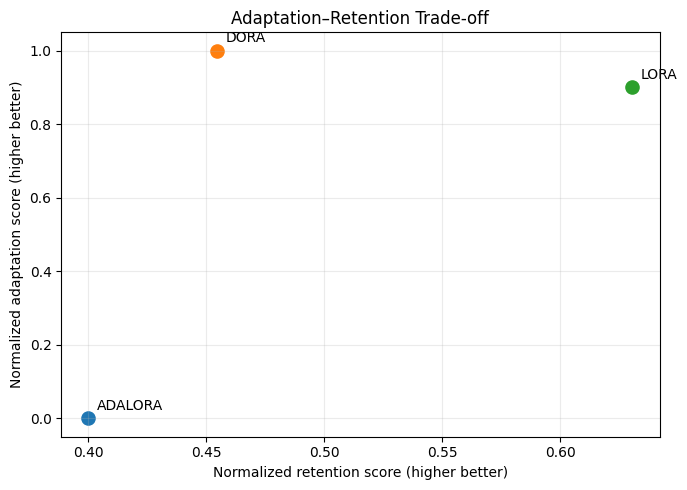

In [7]:
fig,ax=plt.subplots(figsize=(7,5))
for _,r in pts.iterrows():
    ax.scatter(r.retention_score,r.adaptation_score,s=90)
    ax.annotate(r.method.upper(),(r.retention_score,r.adaptation_score),xytext=(6,6),textcoords="offset points")
ax.set(xlabel="Normalized retention score (higher better)",ylabel="Normalized adaptation score (higher better)",
       title="Adaptation–Retention Trade-off")
ax.grid(alpha=.25); plt.tight_layout()
plt.savefig(PLOTS/"adaptation_retention_tradeoff.png",dpi=220); plt.show()

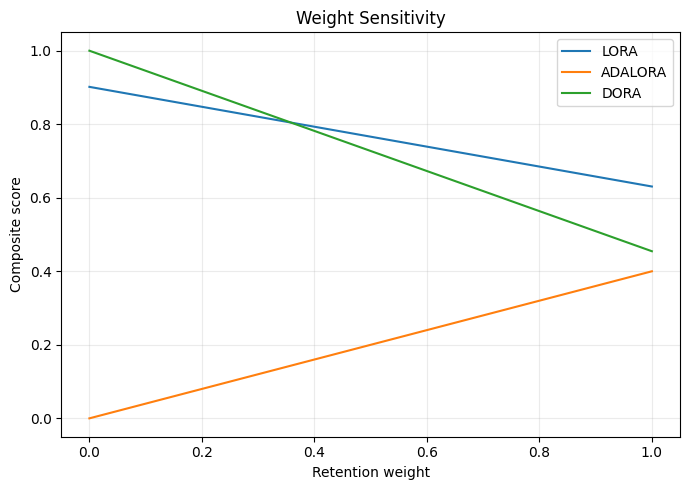

In [8]:
fig,ax=plt.subplots(figsize=(7,5))
for m in ["lora","adalora","dora"]:
    d=sens[sens.method==m]; ax.plot(d.retention_weight,d.score,label=m.upper())
ax.set(xlabel="Retention weight",ylabel="Composite score",title="Weight Sensitivity")
ax.legend(); ax.grid(alpha=.25); plt.tight_layout()
plt.savefig(PLOTS/"weight_sensitivity.png",dpi=220); plt.show()

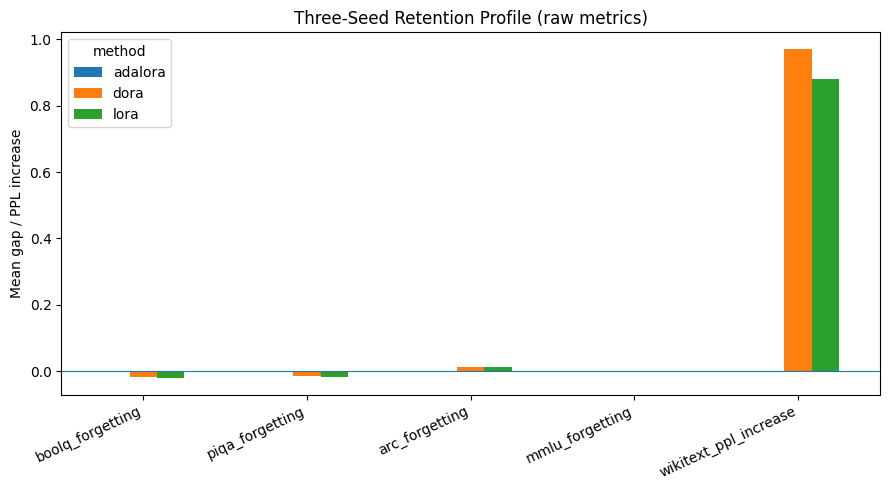

In [9]:
# Raw mean retention profile (note WikiText PPL is a different unit).
profile=means.set_index("method")[ret].T
fig,ax=plt.subplots(figsize=(9,5)); profile.plot(kind="bar",ax=ax)
ax.axhline(0,linewidth=.8); ax.set_ylabel("Mean gap / PPL increase")
ax.set_title("Three-Seed Retention Profile (raw metrics)")
plt.xticks(rotation=25,ha="right"); plt.tight_layout()
plt.savefig(PLOTS/"retention_profile_raw.png",dpi=220); plt.show()

In [10]:
def clean(x):
    if isinstance(x,np.generic): return x.item()
    if isinstance(x,dict): return {str(k):clean(v) for k,v in x.items()}
    if isinstance(x,list): return [clean(v) for v in x]
    return x

record={
 "phase":"phase5_forgetting_aware_tradeoff_analysis","seeds":[42,123,2026],
 "methods":["lora","adalora","dora"],
 "normalization":"Per-probe min-max across method-level 3-seed means; 0 best loss, 1 worst loss.",
 "retention_score":"1 - mean normalized loss across 5 probes",
 "adaptation_score":"min-max normalized mean SAMSum ROUGE-L gain",
 "composite":"(1-w)*adaptation_score + w*retention_score; w swept 0..1",
 "components":analysis.to_dict("records"),"pareto":pts.to_dict("records"),
 "equal_weight":equal[["method","score"]].to_dict("records"),
 "winner_ranges":ranges.to_dict("records"),
 "limitations":["n=3 seeds; descriptive only","Composite depends on normalization and probe set",
                "Sensitivity/Pareto analysis should accompany any composite ranking"]
}
with open(RESULTS/"phase5_final.json","w") as f: json.dump(clean(record),f,indent=2)
print("PHASE 5 COMPLETE ✅")
print("Results:",RESULTS); print("Plots:",PLOTS)

PHASE 5 COMPLETE ✅
Results: /content/drive/MyDrive/forgetting-aware-peft/phase5_forgetting_aware/results
Plots: /content/drive/MyDrive/forgetting-aware-peft/phase5_forgetting_aware/plots


## Interpretation

Use **Pareto efficiency and the full weight-sensitivity sweep** as the primary evidence. The equal-weight score is only one descriptive operating point.

Phase 5 establishes the baseline adaptation–retention frontier that a later forgetting-aware training method should try to improve.